# CIE 2 – Activity 2: Simple House Price Prediction
**Course:** Machine Learning [ADPC509] | **Class:** T.Y. B.Tech (AI & DS) | **Academic Year:** 2026-27

**Name:** Purva Mehetre | **Roll No.:** AD3237 | **Division:** B


## Step 1: Select and understand the dataset
- **Dataset:** California Housing Prices (1990 census data, one row per block group)
- **Source:** https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv (original data from the 1990 U.S. Census, StatLib repository)
- **Target (y):** `median_house_value` (US dollars, continuous)
- **Input feature (X):** `median_income` (income in tens of thousands of dollars)

## Step 2: Load and inspect the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('california_housing.csv')
print('Rows:', df.shape[0], '| Columns:', df.shape[1])
display(df.head())
df.info()

Rows: 20640 | Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [2]:
display(df.describe().round(2))
print('Missing values:')
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64
Duplicate rows: 0


`total_bedrooms` has missing values. It is not used as an input feature, but it is filled with the median to keep the data clean.

In [3]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())
print('Max house value:', df['median_house_value'].max())
print('Rows at this maximum:', (df['median_house_value'] == df['median_house_value'].max()).sum())

Max house value: 500001.0
Rows at this maximum: 965


The house value is capped at 500001, so these rows do not show the real price. They would bend the regression line, so these rows are removed.

In [4]:
df = df[df['median_house_value'] < 500001].reset_index(drop=True)
print('Rows after removing capped values:', len(df))

Rows after removing capped values: 19675


## Step 3: Select input feature and target

In [5]:
X = df[['median_income']]
y = df['median_house_value']
print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (19675, 1) | y shape: (19675,)


Areas with higher income can usually afford costlier houses, so `median_income` should be relevant to price. No ID column is used.

## Step 4: Visualise the relationship

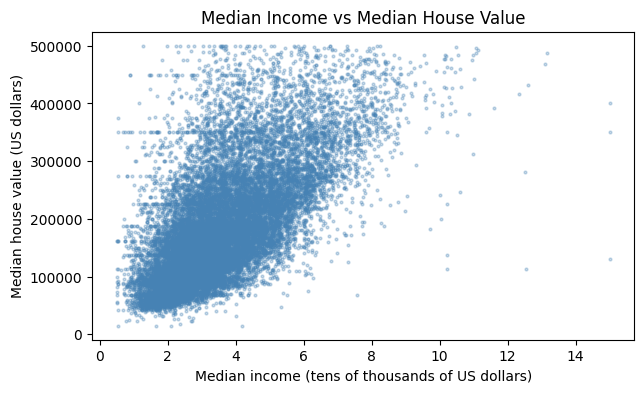

In [6]:
plt.figure(figsize=(7, 4))
plt.scatter(X['median_income'], y, s=4, alpha=0.3, color='steelblue')
plt.title('Median Income vs Median House Value')
plt.xlabel('Median income (tens of thousands of US dollars)')
plt.ylabel('Median house value (US dollars)')
plt.show()

The relationship is positive: house value rises with income, though with a wide spread. A visible relationship does not prove that income causes higher prices.

## Step 5: Split the data

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training records:', len(X_train))
print('Testing records :', len(X_test))

Training records: 15740
Testing records : 3935


The training set is used to learn the model parameters, and the test set is kept unseen to check performance on new data.

## Step 6: Train Linear Regression

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

intercept = model.intercept_
slope = model.coef_[0]
print(f'Intercept: {intercept:.2f}')
print(f'Coefficient (slope): {slope:.2f}')
print(f'Equation: House value = {intercept:.2f} + {slope:.2f} x median_income')

Intercept: 46223.84
Coefficient (slope): 39789.25
Equation: House value = 46223.84 + 39789.25 x median_income


- **Slope:** for every 1 unit (about $10,000) increase in median income, the predicted house value increases by the slope amount.
- **Intercept:** the predicted value when income is 0. It is only a mathematical starting point, not a realistic case.

## Step 7: Generate predictions

In [9]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Median income': X_test['median_income'].values,
    'Actual value': y_test.values,
    'Predicted value': y_pred.round(0),
})
comparison['Difference'] = (comparison['Actual value'] - comparison['Predicted value']).round(0)
comparison.head(10)

,Median income,Actual value,Predicted value,Difference
0,1.8357,104200.0,119265.0,-15065.0
1,4.2109,171200.0,213772.0,-42572.0
2,4.0481,97300.0,207295.0,-109995.0
3,3.5380,102700.0,186998.0,-84298.0
4,2.2000,116500.0,133760.0,-17260.0
5,1.1326,104800.0,91289.0,13511.0
6,2.5434,67300.0,147424.0,-80124.0
7,1.5714,43000.0,108749.0,-65749.0
8,2.9821,162000.0,164879.0,-2879.0
9,5.3072,132700.0,257393.0,-124693.0


Some predictions are close, but others differ by tens of thousands of dollars, because income alone cannot explain the full price.

## Step 8: Evaluate the model

In [10]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE  : {mae:,.2f}')
print(f'MSE  : {mse:,.2f}')
print(f'RMSE : {rmse:,.2f}')
print(f'R2   : {r2:.4f}')

MAE  : 57,910.58
MSE  : 5,785,042,656.20
RMSE : 76,059.47
R2   : 0.4198



- On average the predictions are about $58,000 off (MAE), and RMSE is higher because big errors are penalised more. R² is about 0.42, so income alone explains roughly 42% of the variation in house value. This is moderate, which is expected for a one-feature model.

## Step 9: Actual vs predicted

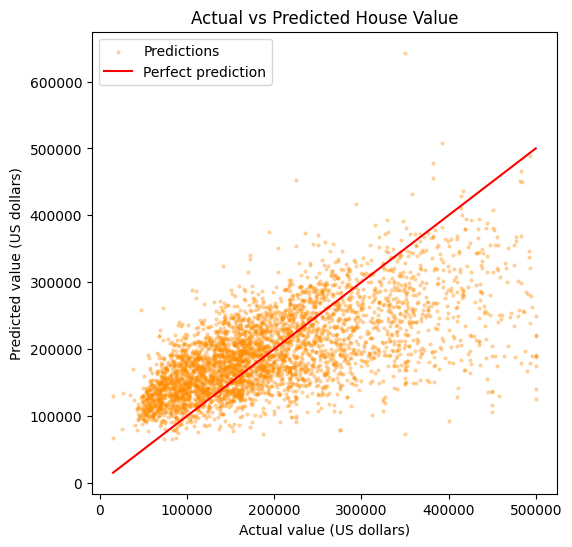

In [11]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=4, alpha=0.3, color='darkorange', label='Predictions')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color='red', label='Perfect prediction')
plt.title('Actual vs Predicted House Value')
plt.xlabel('Actual value (US dollars)')
plt.ylabel('Predicted value (US dollars)')
plt.legend()
plt.show()

The points are scattered widely around the red line, and the model gives similar predictions to houses with very different actual prices. This shows only moderate performance, with large errors for very cheap and expensive areas.

## Step 10: Predict a new example and conclude

In [12]:
new_income = 5.0      # about $50,000, inside the training range (0.5 to 15)
new_pred = model.predict(pd.DataFrame({'median_income': [new_income]}))[0]
print(f'Predicted median house value for income {new_income}: ${new_pred:,.2f}')

Predicted median house value for income 5.0: $245,170.08


## Conclusion
A Linear Regression model was trained on the California housing data (19,675 rows after removing capped values) using `median_income` to predict `median_house_value`, with an 80:20 split. The model gave R² of about 0.42 and MAE of about $58,000. For a median income of 5.0, the predicted house value is about $245,000.

**Limitations:** Only one feature is used, but prices also depend on location, house age, number of rooms and proximity to the ocean. The data is from 1990 and has a single train-test split, so the results are only a basic estimate.